# Olist E-Commerce: Business Insights and Cohort Analysis

This notebook continues from the SQL Server join. The SQL output is at **one row per order** and includes customer identity, payment total, product revenue, delivery dates, and an order-level review average.

The notebook uses Pandas to prepare customer cohorts and pivot monthly retention, then uses Python charts to summarize the findings. The source CSV files remain separate in the SQL Server database; this notebook reads the joined SQL result only.

## Questions and metric choices

- Did customers whose first valid purchase order was in 2017 place another valid order in the observed part of 2018?
- How does customer retention change by month after first purchase?
- What does observed historical product revenue suggest about customer value and the top 1% of customers?
- How do delivery time and review score vary across customer states?

**Definitions:** for purchase cohorts, include delivered, shipped, invoiced, processing, and approved orders; exclude canceled, unavailable, and created orders. This counts accepted order activity even when recent orders have not yet been delivered. For realized product revenue and delivery analysis, use delivered orders only. A customer is identified by `customer_unique_id`; product revenue is the sum of item `price` and excludes freight. Historical revenue is a CLV proxy, not a predictive lifetime value. Valid purchase activity in this extract runs through September 3, 2018, so the 2018 results are partial.

## 1. Load the SQL join result

The query is saved beside this notebook as [`Olist_SQL_Join.sql`](Olist_SQL_Join.sql). It first totals items, payments, and reviews by `order_id`, then joins those summaries to orders and customers. This prevents one order with multiple items, payments, or reviews from multiplying the order row.

In [1]:
from pathlib import Path
import math
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data_path = Path("SQL Server/customer_order_analysis.csv")
df = pd.read_csv(data_path, parse_dates=[
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
])

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")
print(f"Unique orders: {df['order_id'].nunique():,}")
preview_columns = [
    "order_id", "customer_unique_id", "order_status",
    "order_purchase_timestamp", "product_revenue", "payment_total",
]
display(df[preview_columns].head(5))

Rows: 99,441
Columns: 14
Unique orders: 99,441


order_id,customer_unique_id,order_status,order_purchase_timestamp,product_revenue,payment_total
00063b381e2406b52ad429470734ebd5,3fb97204945ca0c01bcf3eee6031c5f1,delivered,2018-07-27 17:21:27,45.00,57.98
0006ec9db01a64e59a68b2c340bf65a7,7ed0ea20347f67fe61d1c99fdf8556ae,delivered,2018-07-24 17:04:17,74.00,97.32
000e906b789b55f64edcb1f84030f90d,3588484a539617d91500764822230fb6,delivered,2017-11-21 18:54:23,21.99,33.84
00143d0f86d6fbd9f9b38ab440ac16f5,bb8a37225e0279ac8a274c9765617eaf,delivered,2017-10-16 15:29:43,63.99,109.29
0017afd5076e074a48f1f1a4c7bac9c5,98758d88bf4b8eef1372ddee45d63178,delivered,2017-04-06 22:16:10,809.10,853.39


## 2. Check the joined table and set the analysis populations

We check that the SQL output has one row per order. Cohorts use delivered, shipped, invoiced, processing, and approved orders; canceled, unavailable, and created orders are excluded. This keeps recent accepted orders even if they were still in transit at the data cutoff. Product revenue and delivery metrics use delivered orders only. Missing reviews stay missing; they are not replaced with made-up scores.

In [2]:
print("Duplicate order IDs:", df["order_id"].duplicated().sum())
print("\nMissing values by field:")
print(df.isna().sum().to_string())
print("\nOrder statuses:")
print(df["order_status"].value_counts().to_string())

purchase_statuses = ["delivered", "shipped", "invoiced", "processing", "approved"]
purchases = df.loc[df["order_status"].isin(purchase_statuses)].copy()
purchases = purchases.dropna(subset=["order_purchase_timestamp", "customer_unique_id"])
purchases["purchase_month"] = purchases["order_purchase_timestamp"].dt.to_period("M")

delivered = df.loc[df["order_status"].eq("delivered")].copy()
delivered = delivered.dropna(subset=["order_purchase_timestamp", "customer_unique_id"])
delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

print(f"\nValid purchase orders: {len(purchases):,}")
print(f"Customers with a valid purchase: {purchases['customer_unique_id'].nunique():,}")
print("Valid purchase date range:", purchases["order_purchase_timestamp"].min(), "to", purchases["order_purchase_timestamp"].max())
print(f"Delivered orders for revenue and delivery analysis: {len(delivered):,}")
print("Delivered orders without a review:", delivered["average_review_score"].isna().sum())
print("Delivered orders without a delivery date:", delivered["delivery_days"].isna().sum())

Duplicate order IDs: 0

Missing values by field:
order_id                            0
customer_id                         0
customer_unique_id                  0
customer_state                      0
order_status                        0
order_purchase_timestamp            0
order_delivered_customer_date    2965
order_estimated_delivery_date       0
product_revenue                   775
freight_total                     775
payment_total                       1
average_review_score              768
item_count                          0
review_count                        0

Order statuses:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2

Valid purchase orders: 98,202
Customers with a valid purchase: 94,986
Valid purchase date range: 2016-09-04 21:15:19 to 2018-09-03 09:06:57
Delivered orders for revenue and delivery analysis: 96,478
Delivered orders with

## 3. Build monthly customer cohorts

**Cohort** means a group of customers who made their first valid order in the same month. For example, the `2017-01` cohort contains customers whose first valid order was in January 2017. Month 0 is that first month; month 1 is the next calendar month. The retention rate is the number of customers from that original group who ordered again in a given month, divided by the original group size. Month 0 is always 100% because it defines the group.

The heatmap includes every monthly cohort in the complete-month analysis and focuses on months 1–12, so it shows repeat orders rather than the automatic 100% first month. Cohort size is shown in the row label: percentages from very small cohorts are unstable and should be read with that sample size in mind. The latest valid order is dated September 3, 2018, so September is only partial: the cohort heatmap uses complete months through August. The separate 2017-to-2018 business question still includes valid September orders.

In the preview, each cell shows `returning customers / cohort size (retention %)`. `0/290 (0.00%)` means the month was observed and no customer returned; `Not yet observed` means the dataset had not reached that follow-up month.

In [3]:
last_complete_month = purchases["purchase_month"].max() - 1
cohort_purchases = purchases.loc[purchases["purchase_month"] <= last_complete_month].copy()

first_purchase = cohort_purchases.groupby("customer_unique_id")["purchase_month"].min()
cohort_purchases["cohort_month"] = cohort_purchases["customer_unique_id"].map(first_purchase)

cohort_purchases["month_number"] = (
    (cohort_purchases["purchase_month"].dt.year - cohort_purchases["cohort_month"].dt.year) * 12
    + cohort_purchases["purchase_month"].dt.month
    - cohort_purchases["cohort_month"].dt.month
)

cohort_sizes = first_purchase.value_counts().sort_index().rename("cohort_size")
monthly_activity = (
    cohort_purchases.groupby(["cohort_month", "month_number"])["customer_unique_id"]
    .nunique()
    .rename("active_customers")
    .reset_index()
)
monthly_activity["cohort_size"] = monthly_activity["cohort_month"].map(cohort_sizes)
monthly_activity["retention_rate"] = (
    monthly_activity["active_customers"] / monthly_activity["cohort_size"]
)

retention = monthly_activity.pivot(
    index="cohort_month", columns="month_number", values="retention_rate"
)

last_month = last_complete_month
last_age = (last_month.year - retention.index[0].year) * 12 + last_month.month - retention.index[0].month
retention = retention.reindex(columns=range(last_age + 1))

for cohort_month in retention.index:
    observed_age = (last_month.year - cohort_month.year) * 12 + last_month.month - cohort_month.month
    observed_columns = range(observed_age + 1)
    retention.loc[cohort_month, observed_columns] = retention.loc[cohort_month, observed_columns].fillna(0)

print("Cohort months:", len(retention))
print("Complete months included:", cohort_purchases["purchase_month"].min(), "to", last_complete_month)
print("Largest observed cohort size:", int(cohort_sizes.max()))

monthly_counts = monthly_activity.set_index(["cohort_month", "month_number"])["active_customers"]
retention_preview = pd.DataFrame(index=retention.index)
retention_preview["cohort_size"] = cohort_sizes

for age in range(1, 7):
    values = []
    for cohort_month in retention.index:
        observed_age = (last_month.year - cohort_month.year) * 12 + last_month.month - cohort_month.month
        if age > observed_age:
            values.append("Not yet observed")
        else:
            returned = int(monthly_counts.get((cohort_month, age), 0))
            size = int(cohort_sizes.loc[cohort_month])
            rate = returned / size * 100
            values.append(f"{returned}/{size} ({rate:.2f}%)")
    retention_preview[f"month_{age}"] = values

print("\nRetention preview: returners / cohort size (retention %)")
display(retention_preview.head(8).reset_index())

Cohort months: 23
Complete months included: 2016-09 to 2018-08
Largest observed cohort size: 7188

Retention preview: returners / cohort size (retention %)


cohort_month,cohort_size,month_1,month_2,month_3,month_4,month_5,month_6
2016-09,2,0/2 (0.00%),0/2 (0.00%),0/2 (0.00%),0/2 (0.00%),0/2 (0.00%),0/2 (0.00%)
2016-10,290,0/290 (0.00%),0/290 (0.00%),0/290 (0.00%),0/290 (0.00%),0/290 (0.00%),1/290 (0.34%)
2016-12,1,1/1 (100.00%),0/1 (0.00%),0/1 (0.00%),0/1 (0.00%),0/1 (0.00%),0/1 (0.00%)
2017-01,752,3/752 (0.40%),2/752 (0.27%),1/752 (0.13%),3/752 (0.40%),1/752 (0.13%),3/752 (0.40%)
2017-02,1690,4/1690 (0.24%),5/1690 (0.30%),2/1690 (0.12%),7/1690 (0.41%),2/1690 (0.12%),4/1690 (0.24%)
2017-03,2571,13/2571 (0.51%),9/2571 (0.35%),10/2571 (0.39%),9/2571 (0.35%),4/2571 (0.16%),4/2571 (0.16%)
2017-04,2325,14/2325 (0.60%),5/2325 (0.22%),4/2325 (0.17%),7/2325 (0.30%),6/2325 (0.26%),8/2325 (0.34%)
2017-05,3541,17/3541 (0.48%),17/3541 (0.48%),14/3541 (0.40%),11/3541 (0.31%),12/3541 (0.34%),15/3541 (0.42%)


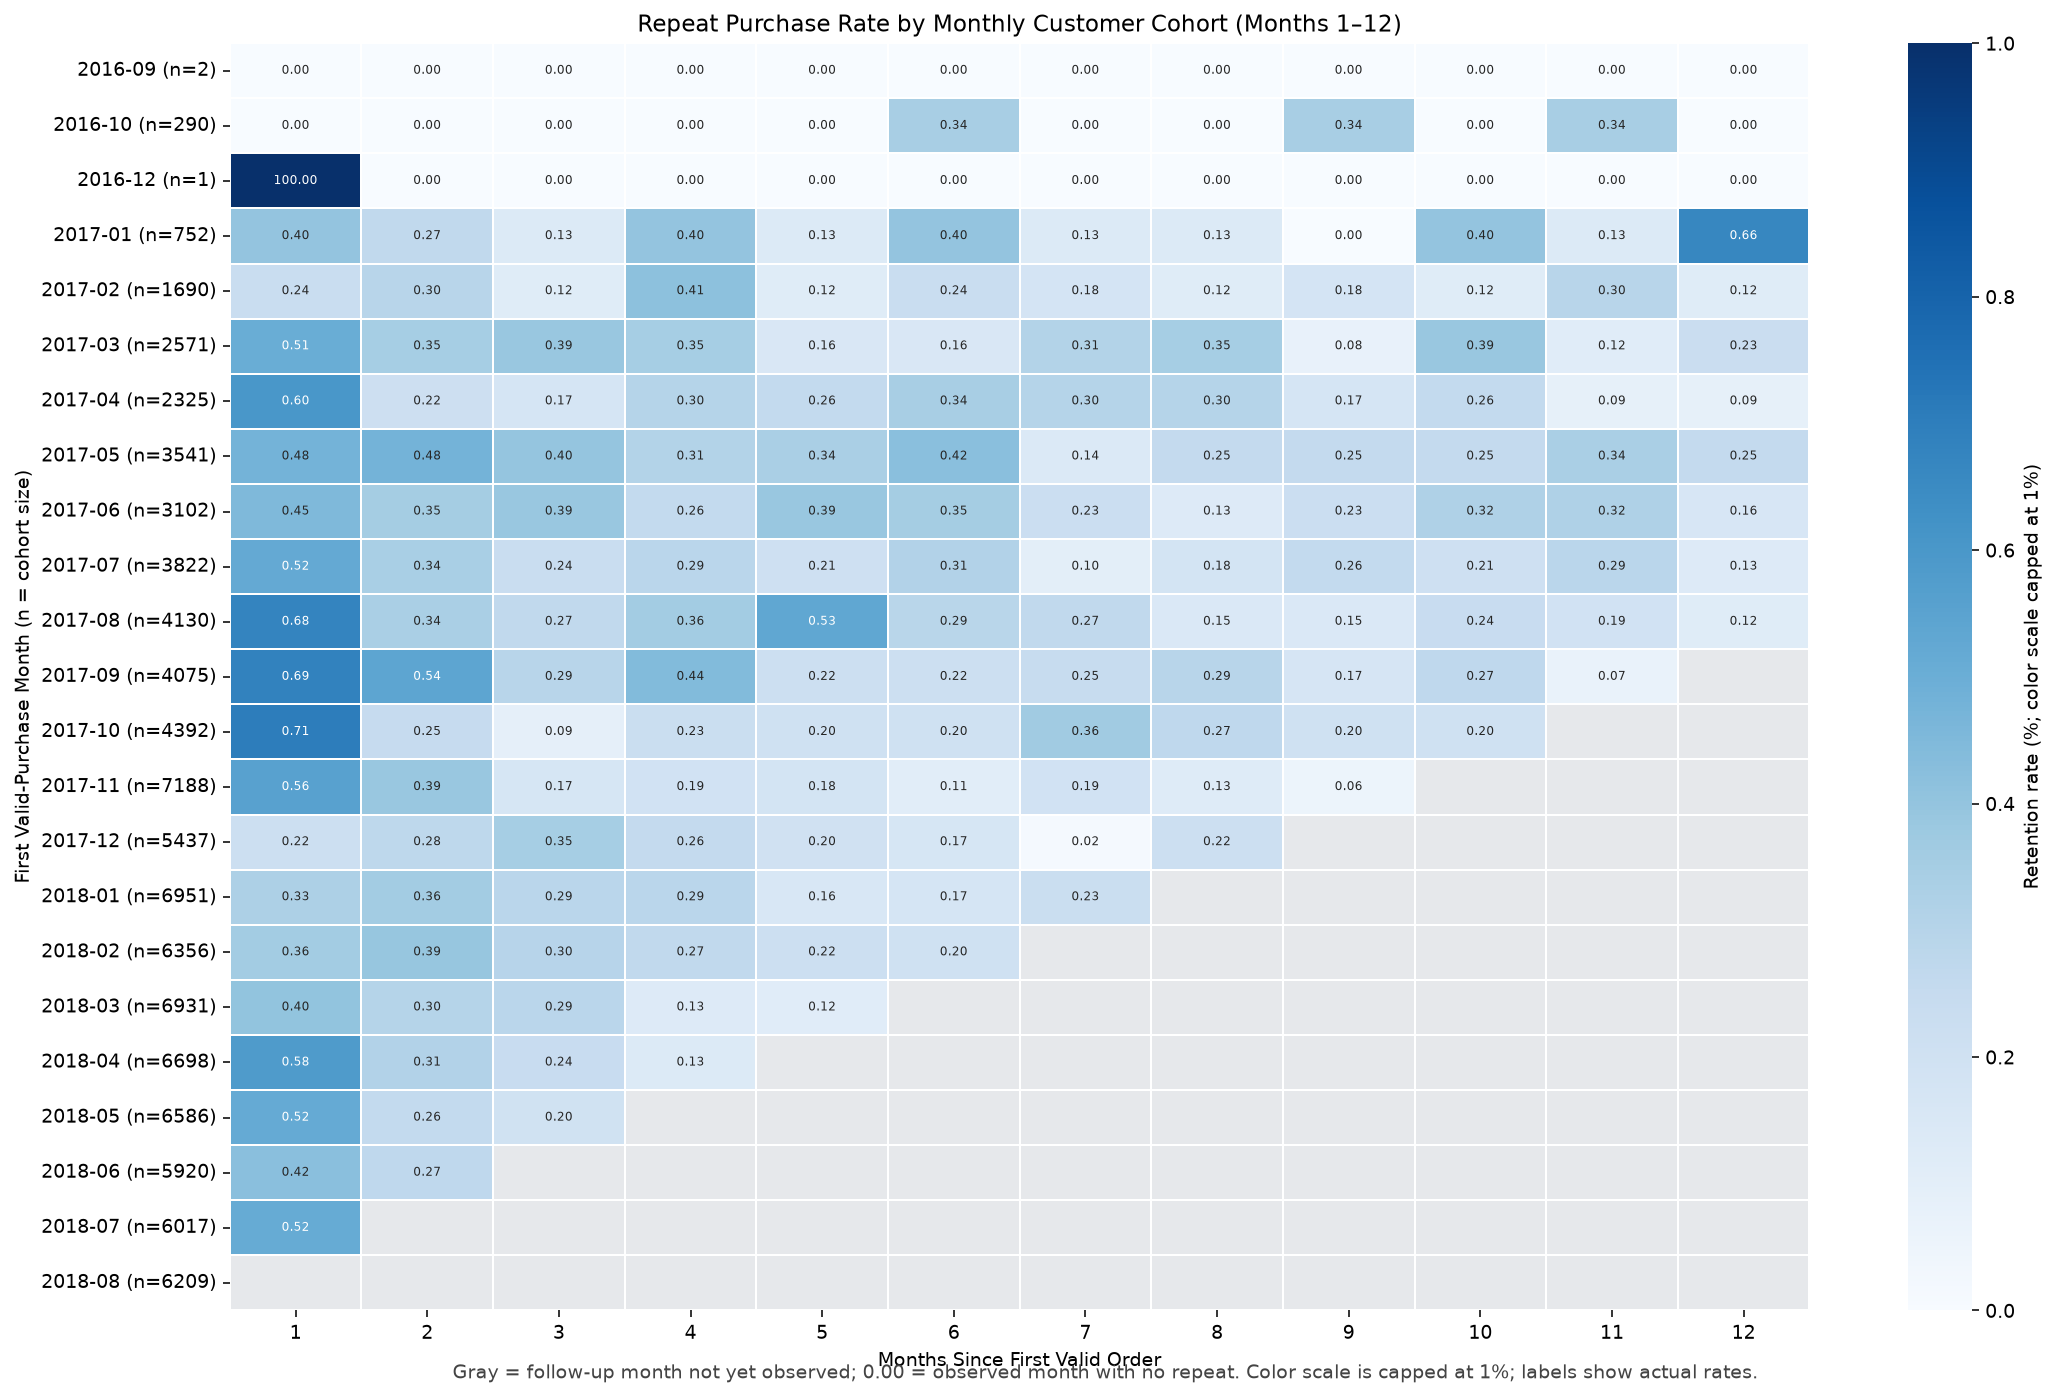

In [4]:
heatmap_data = retention.loc[:, 1:12].mul(100)
heatmap_data.index = [
    f"{cohort_month} (n={int(cohort_sizes.loc[cohort_month])})"
    for cohort_month in heatmap_data.index
]

plt.figure(figsize=(16, 10))
retention_colors = sns.color_palette("Blues", as_cmap=True)
retention_colors.set_bad("#E6E8EB")
sns.heatmap(
    heatmap_data,
    mask=heatmap_data.isna(),
    cmap=retention_colors,
    vmin=0,
    vmax=1.0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 6},
    linewidths=0.25,
    cbar_kws={"label": "Retention rate (%; color scale capped at 1%)"},
)
plt.title("Repeat Purchase Rate by Monthly Customer Cohort (Months 1–12)")
plt.xlabel("Months Since First Valid Order")
plt.ylabel("First Valid-Purchase Month (n = cohort size)")
plt.figtext(
    0.5, 0.01,
    "Gray = follow-up month not yet observed; 0.00 = observed month with no repeat. Color scale is capped at 1%; labels show actual rates.",
    ha="center", fontsize=10, color="#444444",
)
plt.tight_layout()
plt.show()

## Export the cohort matrix for Power BI

This saves the Pandas cohort result as a small long-format file. It includes every cohort, its size, returning-customer counts, and retention rate. Months beyond the complete data window stay blank, not zero.

In [5]:
cohort_rows = []

for cohort_month in retention.index:
    cohort_size = int(cohort_sizes.loc[cohort_month])
    observed_age = (
        (last_month.year - cohort_month.year) * 12
        + last_month.month - cohort_month.month
    )

    for month_number in range(1, 13):
        if month_number <= observed_age:
            returning = int(monthly_counts.get((cohort_month, month_number), 0))
            rate = returning / cohort_size
        else:
            returning = None
            rate = None

        cohort_rows.append({
            "cohort_month": cohort_month.to_timestamp(),
            "cohort_size": cohort_size,
            "month_number": month_number,
            "returning_customers": returning,
            "retention_rate": rate,
        })

cohort_for_powerbi = pd.DataFrame(cohort_rows)
cohort_for_powerbi.to_csv("Python Output/cohort_retention_for_powerbi.csv", index=False)

print(f"Rows exported: {len(cohort_for_powerbi):,}")
print("File: Python Output/cohort_retention_for_powerbi.csv")
display(cohort_for_powerbi.head(10))

Rows exported: 276
File: Python Output/cohort_retention_for_powerbi.csv


cohort_month,cohort_size,month_number,returning_customers,retention_rate
2016-09-01,2,1,0.0,0.0
2016-09-01,2,2,0.0,0.0
2016-09-01,2,3,0.0,0.0
2016-09-01,2,4,0.0,0.0
2016-09-01,2,5,0.0,0.0
2016-09-01,2,6,0.0,0.0
2016-09-01,2,7,0.0,0.0
2016-09-01,2,8,0.0,0.0
2016-09-01,2,9,0.0,0.0
2016-09-01,2,10,0.0,0.0


## 4. Answer the CEO's 2017-to-2018 question

A 2017 customer is counted as returned if they have at least one valid order dated in the observed 2018 data. We include shipped and processing orders because they represent order activity even if delivery had not happened by the extract date. Canceled, unavailable, and created orders are excluded.

In [6]:
customers_acquired_2017 = first_purchase[first_purchase.dt.year.eq(2017)].index
purchases_from_2017_customers = purchases[
    purchases["customer_unique_id"].isin(customers_acquired_2017)
]
returned_in_observed_2018 = purchases_from_2017_customers.loc[
    purchases_from_2017_customers["order_purchase_timestamp"].dt.year.eq(2018),
    "customer_unique_id",
].nunique()

cohort_2017_size = len(customers_acquired_2017)
return_rate_2018 = returned_in_observed_2018 / cohort_2017_size

print(f"Customers first acquired in 2017: {cohort_2017_size:,}")
print(f"Bought again during observed 2018: {returned_in_observed_2018:,}")
print(f"Observed 2018 return rate: {return_rate_2018:.2%}")
print("Last valid purchase in the extract:", purchases["order_purchase_timestamp"].max().date())

Customers first acquired in 2017: 43,025
Bought again during observed 2018: 662
Observed 2018 return rate: 1.54%
Last valid purchase in the extract: 2018-09-03


## 5. Historical customer value and Power Users

We sum `product_revenue` for each customer across delivered orders. This gives historical product revenue during the dataset window. It is useful for ranking customers and describing observed value, but it is not a forecast of future customer value.

In [7]:
customer_value = (
    delivered.groupby("customer_unique_id")
    .agg(
        historical_product_revenue=("product_revenue", "sum"),
        delivered_orders=("order_id", "nunique"),
    )
    .sort_values("historical_product_revenue", ascending=False)
)

top_count = max(1, math.ceil(len(customer_value) * 0.01))
power_users = customer_value.head(top_count).copy()
revenue_total = customer_value["historical_product_revenue"].sum()
power_user_share = power_users["historical_product_revenue"].sum() / revenue_total
repeat_customers = customer_value["delivered_orders"].gt(1).sum()

print(f"Customers used for value analysis: {len(customer_value):,}")
print(f"Median historical product revenue per customer: ${customer_value['historical_product_revenue'].median():,.2f}")
print(f"Mean historical product revenue per customer: ${customer_value['historical_product_revenue'].mean():,.2f}")
print(f"Repeat customers in the observed period: {repeat_customers:,} ({repeat_customers / len(customer_value):.2%})")
print(f"Top 1% group size: {top_count:,}")
print(f"Top 1% share of delivered product revenue: {power_user_share:.2%}")
print("\nTop 10 customers by observed product revenue:")
print(power_users.head(10).round(2).to_string())

Customers used for value analysis: 93,358
Median historical product revenue per customer: $89.73
Mean historical product revenue per customer: $141.62
Repeat customers in the observed period: 2,801 (3.00%)
Top 1% group size: 934
Top 1% share of delivered product revenue: 11.47%

Top 10 customers by observed product revenue:
                                  historical_product_revenue  delivered_orders
customer_unique_id                                                            
0a0a92112bd4c708ca5fde585afaa872                     13440.0                 1
da122df9eeddfedc1dc1f5349a1a690c                      7388.0                 2
763c8b1c9c68a0229c42c9fc6f662b93                      7160.0                 1
dc4802a71eae9be1dd28f5d788ceb526                      6735.0                 1
459bef486812aa25204be022145caa62                      6729.0                 1
ff4159b92c40ebe40454e3e6a7c35ed6                      6499.0                 1
4007669dec559734d6f53e029e360987          

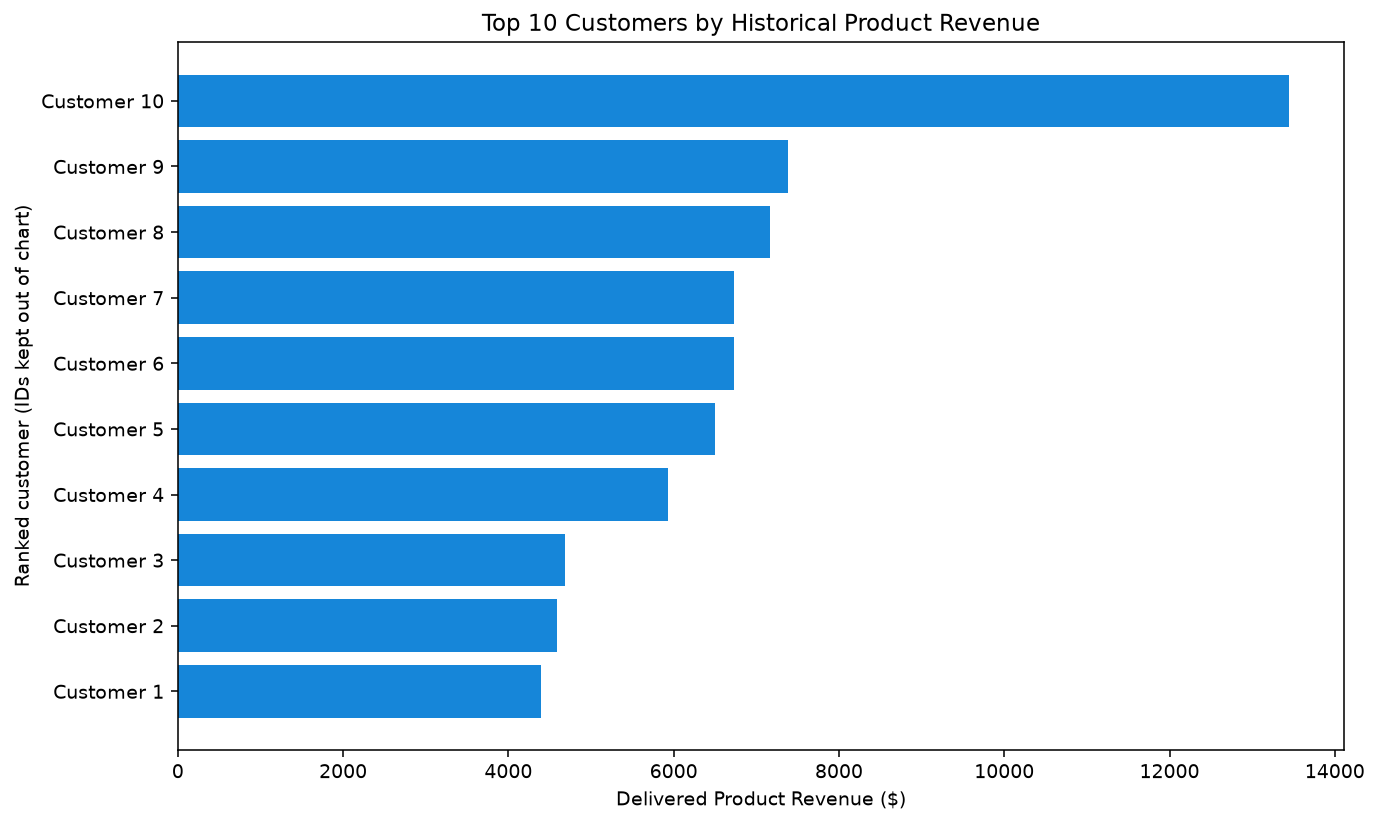

In [8]:
top_ten = power_users.head(10).sort_values("historical_product_revenue")
labels = [f"Customer {i}" for i in range(1, len(top_ten) + 1)]

plt.figure(figsize=(10, 6))
plt.barh(labels, top_ten["historical_product_revenue"], color="#1686D9")
plt.title("Top 10 Customers by Historical Product Revenue")
plt.xlabel("Delivered Product Revenue ($)")
plt.ylabel("Ranked customer (IDs kept out of chart)")
plt.tight_layout()
plt.show()

## 6. Bonus: delivery time and review score by state

Delivery time is measured from purchase to customer delivery. Review scores are averaged per order in SQL first, so an order with multiple review records still contributes one order-level score. We compare state averages and report correlation as descriptive only; it does not show that delivery time caused a score change.

In [9]:
state_summary = (
    delivered.groupby("customer_state")
    .agg(
        average_delivery_days=("delivery_days", "mean"),
        average_review_score=("average_review_score", "mean"),
        delivered_orders=("order_id", "nunique"),
        reviewed_orders=("average_review_score", "count"),
    )
    .dropna(subset=["average_delivery_days", "average_review_score"])
)

pearson_corr = state_summary["average_delivery_days"].corr(state_summary["average_review_score"])
spearman_corr = state_summary["average_delivery_days"].corr(
    state_summary["average_review_score"], method="spearman"
)

print(f"States with both delivery and review data: {len(state_summary)}")
print(f"Pearson correlation across state averages: {pearson_corr:.3f}")
print(f"Spearman correlation across state averages: {spearman_corr:.3f}")
print("\nFive states with the longest average delivery time:")
print(state_summary.sort_values("average_delivery_days", ascending=False).head(5).round(2).to_string())

States with both delivery and review data: 27
Pearson correlation across state averages: -0.454
Spearman correlation across state averages: -0.490

Five states with the longest average delivery time:
                average_delivery_days  average_review_score  delivered_orders  reviewed_orders
customer_state                                                                                
RR                              29.39                  3.90                41               41
AP                              27.19                  4.24                67               66
AM                              26.43                  4.24               145              144
AL                              24.54                  3.85               397              394
PA                              23.77                  3.91               946              933


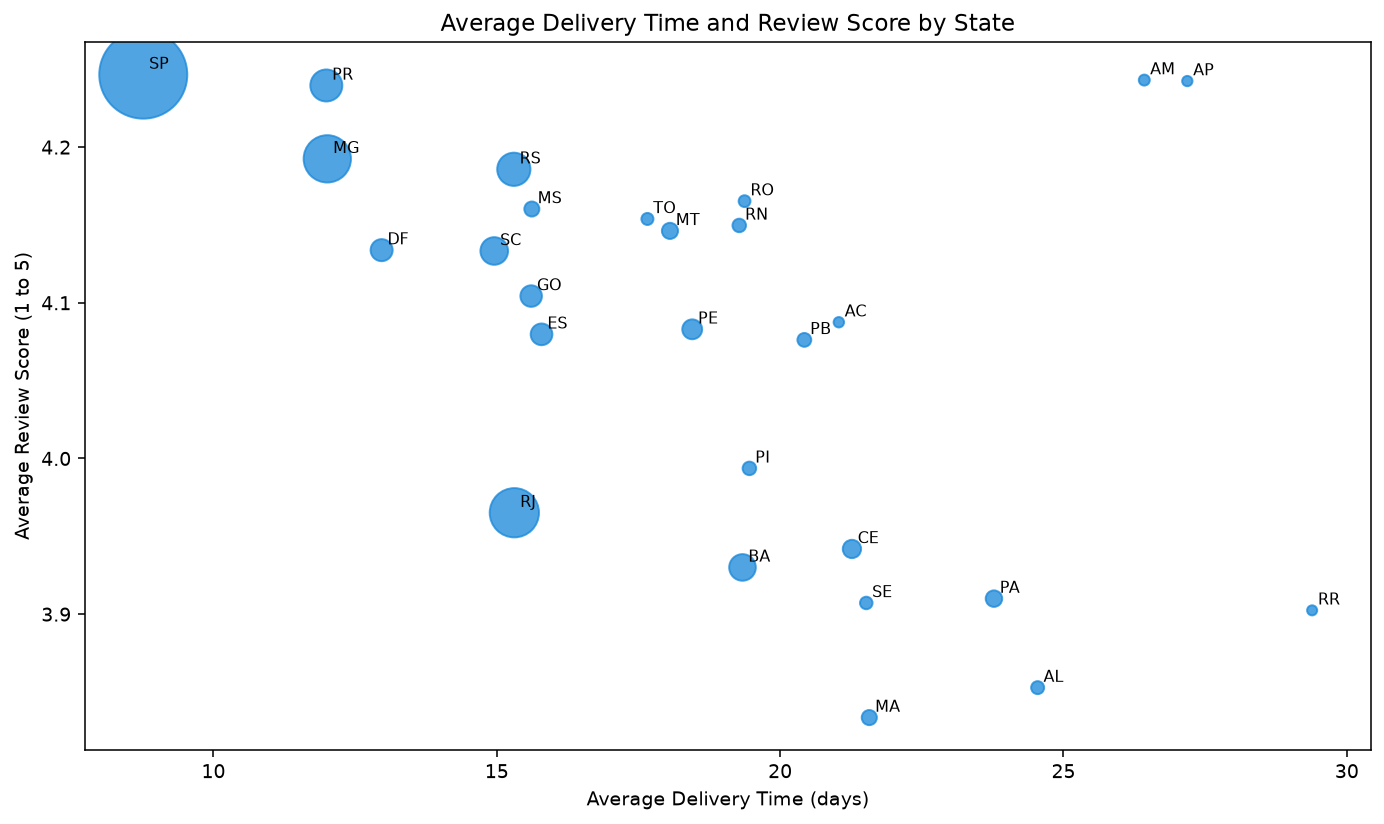

In [10]:
plt.figure(figsize=(10, 6))
plt.scatter(
    state_summary["average_delivery_days"],
    state_summary["average_review_score"],
    s=state_summary["delivered_orders"] / 20 + 25,
    alpha=0.75,
    color="#1686D9",
)
for state, row in state_summary.iterrows():
    plt.annotate(state, (row["average_delivery_days"], row["average_review_score"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.title("Average Delivery Time and Review Score by State")
plt.xlabel("Average Delivery Time (days)")
plt.ylabel("Average Review Score (1 to 5)")
plt.tight_layout()
plt.show()

## 7. Executive readout

The key conclusion is that repeat purchasing is limited in the observed data: **43,025** customers first had a valid purchase order in 2017, and **662 (1.54%)** placed another valid order during the observed part of 2018. The cohort heatmap shows when repeat orders occur after acquisition.

The top 1% of customers contributed **11.47%** of delivered product revenue in this observation window. Treat this as a concentration signal, then validate customer value over a longer period and with margin data before making investment decisions.

Average delivery time and review score move in the direction shown by the state-level correlation (**Pearson r = -0.454**), but state averages are observational and may be affected by order mix, distance, and small state sample sizes.

### Recommendations

1. Track post-purchase return rates by cohort and test follow-up offers or replenishment reminders against a holdout group.
2. Review the high-value customer group and compare its product mix and repeat behavior before designing a retention program.
3. Investigate states with slower delivery and weaker reviews; compare order volumes and delivery routes before attributing the review gap to shipping time.

### Limitations

- The raw orders table has timestamps through October 17, 2018, but the last valid order status in this cohort definition is September 3, 2018. The 2018 calendar year and later cohort ages are incomplete.
- `customer_unique_id` is the customer key; `customer_id` identifies an order-level customer record.
- Customer value is historical product revenue, not predictive CLV or profit. Costs, margins, marketing spend, and future behavior are not supplied.
- Reviews are missing for some delivered orders. Correlation across state averages is descriptive, not causal.